In [3]:
import os
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

In [4]:
in_dir = "../ml_dataset/output/ml_features/"

in_file = os.path.join(
    in_dir,
    "forecast_features_p90.csv",
)

df = pd.read_csv(in_file)
df['event'] = (df['impact'] == 1) & (df['ar_present'] == 1)
df['event'] = df['event'].astype(int)
df

,impact_date,init_date,lead_time,impact,ar_present,ivt_pct,uv_pct,qpf_pct,freezing_level_pct,ar_index,event
0,2000-01-02,2000-01-01,24,0,0,75.0,96.7,75.0,0.0,1.00,0
1,2000-01-03,2000-01-02,24,0,0,85.5,95.4,75.0,0.0,1.00,0
2,2000-01-03,2000-01-01,48,0,0,75.0,95.1,75.0,0.0,1.00,0
3,2000-01-04,2000-01-03,24,0,0,75.0,75.0,75.0,0.0,1.00,0
4,2000-01-04,2000-01-02,48,0,0,75.0,75.0,75.0,0.0,1.00,0
...,...,...,...,...,...,...,...,...,...,...,...
51102,2019-12-31,2019-12-28,72,0,0,0.0,97.0,75.0,52.5,1.35,0
51103,2019-12-31,2019-12-27,96,0,0,0.0,98.1,75.0,52.5,1.35,0
51104,2019-12-31,2019-12-26,120,0,0,0.0,94.7,75.0,52.5,1.00,0
51105,2019-12-31,2019-12-25,144,0,0,0.0,85.5,75.0,93.1,1.00,0


In [5]:
def contingency_metrics(y_true, y_pred):
    """
    Compute probability of detection (POD) and False Alarm Ratio (FAR) for any binary forecast.
    POD: The probability that a target is correctly detected when it is actually present (higher = better)
    FAR: The fraction of total detections that are incorrect (i.e., false alarms) (lower = better)
    Using the impacts list as truth, 
    If an impact occurred and the forecast did exceed the Xth percentile QPF for that lead time, it is a HIT (H)
    If an impact occurred and the forecast did not exceed the Xth percentile QPF for that lead time, it is a MISS (M)
    If an impact did not occur and the forecast did exceed the Xth percentile QPF for that lead time, it is a FALSE ALARM (F)
    POD = H / (H + M)
    FAR = F / (H + F)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    hits = np.sum((y_true == 1) & (y_pred == 1))
    misses = np.sum((y_true == 1) & (y_pred == 0))
    false_alarms = np.sum((y_true == 0) & (y_pred == 1))

    pod = hits / (hits + misses) if (hits + misses) > 0 else np.nan
    far = false_alarms / (hits + false_alarms) if (hits + false_alarms) > 0 else np.nan

    return pod, far

def baseline_qpf_metrics(df, feature=None, thresholds=None):

    results = []

    for t in thresholds:

        # --- QPF only ---
        if feature is None:
            y_pred = (df["qpf_pct"] >= t)
            label = "QPF"

        # --- single additional variable ---
        elif isinstance(feature, str):
            y_pred = (df["qpf_pct"] >= t) & (df[feature] >= t)
            label = f"QPF + {feature}"

        # --- multiple variables (tuple or list) ---
        elif isinstance(feature, (tuple, list)):
            y_pred = (df["qpf_pct"] >= t)

            for var in feature:
                y_pred = y_pred & (df[var] >= t)

            label = "QPF + " + " + ".join(feature)

        else:
            raise ValueError("feature must be None, str, or tuple/list")

        y_pred = y_pred.astype(int)

        pod, far = contingency_metrics(df["event"], y_pred)

        results.append({
            "threshold": t,
            "POD": pod,
            "FAR": far,
            "label": label
        })

    return pd.DataFrame(results)

def plot_pod_far(df_metrics, label="QPF only"):
    plt.figure()
    plt.plot(df_metrics["FAR"], df_metrics["POD"], marker="o")
    for i, t in enumerate(df_metrics["threshold"]):
        plt.text(df_metrics["FAR"].iloc[i], df_metrics["POD"].iloc[i], int(t))

    plt.xlabel("False Alarm Rate")
    plt.ylabel("Probability of Detection")
    plt.title(label)
    plt.grid()
    plt.show()

def plot_pod_far_multi(dfs):

    plt.figure(figsize=(7, 7))

    for df_metrics in dfs:
        label = df_metrics["label"].iloc[0]

        plt.plot(
            df_metrics["FAR"],
            df_metrics["POD"],
            marker="o",
            label=label
        )

        # optional: label thresholds
        for i, t in enumerate(df_metrics["threshold"]):
            if t >= 97:  # reduce clutter
                plt.text(
                    df_metrics["FAR"].iloc[i],
                    df_metrics["POD"].iloc[i],
                    int(t),
                    fontsize=8
                )

    plt.xlabel("False Alarm Rate")
    plt.ylabel("Probability of Detection")
    plt.title("POD vs FAR Comparison")
    plt.legend()
    plt.grid()

    plt.xlim(.8, 1)
    plt.ylim(.4, 1)

    plt.show()

def fit_logistic_by_leadtime(df, features):
    models = {}
    aucs = {}

    for lt, sub in df.groupby("lead_time"):

        X = sub[features]
        y = sub["event"]

        model = LogisticRegression(max_iter=2000)
        model.fit(X, y)

        y_prob = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, y_prob)

        models[lt] = model
        aucs[lt] = auc

    return models, aucs

def fit_pooled_model(df, features):
    df = df.copy()

    X = df[features + ["lead_time"]]
    y = df["event"]

    model = LogisticRegression(max_iter=2000)
    model.fit(X, y)

    y_prob = model.predict_proba(X)[:, 1]
    auc = roc_auc_score(y, y_prob)

    return model, auc

def plot_roc_comparison(df, features_multi):
    y = df["event"]

    # QPF-only
    qpf_score = df["qpf_pct"]
    fpr_q, tpr_q, _ = roc_curve(y, qpf_score)
    auc_q = roc_auc_score(y, qpf_score)

    # Multivariate
    model = LogisticRegression(max_iter=2000)
    model.fit(df[features_multi], y)
    multi_score = model.predict_proba(df[features_multi])[:, 1]

    fpr_m, tpr_m, _ = roc_curve(y, multi_score)
    auc_m = roc_auc_score(y, multi_score)

    plt.figure()

    plt.plot(fpr_q, tpr_q, label=f"QPF only (AUC={auc_q:.3f})")
    plt.plot(fpr_m, tpr_m, label=f"Multivariate (AUC={auc_m:.3f})")

    plt.plot([0, 1], [0, 1], "k--")

    plt.xlabel("False Alarm Rate")
    plt.ylabel("Probability of Detection")
    plt.title("ROC Comparison")
    plt.legend()
    plt.grid()
    plt.show()

def compare_fixed_pod(df, features_multi, target_pod=0.8):
    """
    Does adding IVT reduce FAR at same detection?
    """
    y = df["event"]

    # QPF-only scores
    qpf = df["qpf_pct"]

    # Multivariate model
    model = LogisticRegression(max_iter=2000)
    model.fit(df[features_multi], y)
    mscore = model.predict_proba(df[features_multi])[:, 1]

    def find_far_for_pod(score):
        fpr, tpr, thresholds = roc_curve(y, score)

        idx = np.argmin(np.abs(tpr - target_pod))
        # approximate FAR = FPR at that operating point
        return fpr[idx], tpr[idx]

    far_q, pod_q = find_far_for_pod(qpf)
    far_m, pod_m = find_far_for_pod(mscore)

    return {
        "QPF_only": {"FAR": far_q, "POD": pod_q},
        "Multivariate": {"FAR": far_m, "POD": pod_m}
    }

[  0.  75.  90.  91.  92.  93.  94.  95.  96.  97.  98.  99. 100.]


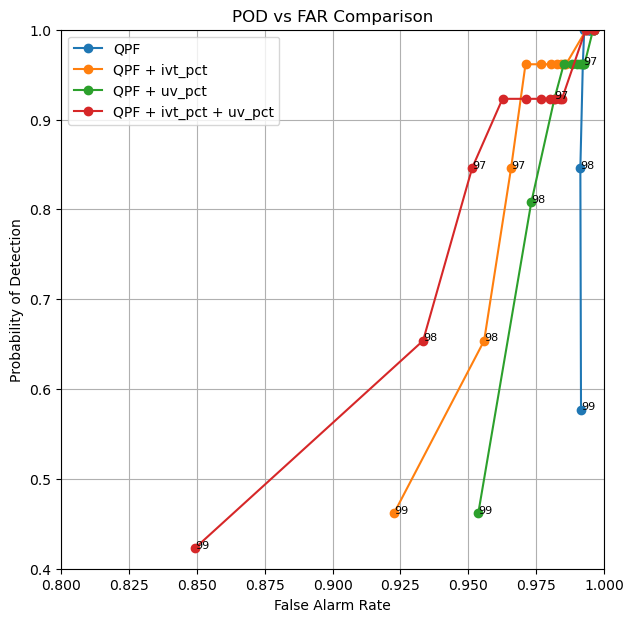

In [6]:
## thresholds for baseline curves
a = np.array([0., 75., 90.])
b = np.arange(91., 100.1, 1)
quantile_arr = np.concatenate((a, b))
print(quantile_arr)
## baseline curves
idx = df['lead_time'] == 24
lt_24 = df.loc[idx]

combined_metrics = []

features = [None, "ivt_pct", "uv_pct", ('ivt_pct', 'uv_pct')]

for f in features:
    qpf_metrics = baseline_qpf_metrics(
        lt_24,
        feature=f,
        thresholds=quantile_arr
    )
    combined_metrics.append(qpf_metrics)

plot_pod_far_multi(combined_metrics)

In [7]:
## ROC comparison
features = ["qpf_pct", "ivt_pct", "z_pct", "uv_pct"]
plot_roc_comparison(df, features)

ValueError: Input contains NaN.

In [ ]:
## lead time sensitivity
features = ["qpf_pct", "ivt_pct", "z_pct", "uv_pct"]

models, aucs = fit_logistic_by_leadtime(df, features)
print(aucs)

In [ ]:
## far reduction at fixed lead time
compare_fixed_pod(df, features, target_pod=0.8)